# WB_Ecomm_Analitycs_2026

In [2]:
import pandas as pd

# Загружаем твой датасет от WB (подставь своё имя файла и расширение)
# Если файл .csv:
df = pd.read_excel('Отчет о продажах по реализации.xlsx')

# Если файл .xlsx:
# df = pd.read_excel('твой_файл_wb.xlsx')

# Смотрим на первые 5 строчек, чтобы проверить структуру данных
print("Успешно загружено! Вот первые строки датасета:")
display(df.head())

# Смотрим, какие колонки у нас есть и сколько всего строк
df.info()

Успешно загружено! Вот первые строки датасета:


,subject_name,brand_name,Артикул поставщика,ts_name,doc_type_name,quantity,retail_price,retail_amount,sale_percent,commission_percent,...,rrd_id,ppvz_reward,acquiring_fee,rebill_logistic_cost,ppvz_vw,return_amount,srid,techSize,chrtID,realizationreport_id
0,Куртки,ozy,ack1,S,NaN,0,0,0,0,0.0,...,18766338925,0.0,0.0,0.0,0.0,1,57493231082658020.0.0,S,282095412.0,44985740
1,Куртки,ozy,ack1,S,NaN,0,0,0,0,0.0,...,18766339181,0.0,0.0,0.0,0.0,1,11115603082488087.0.0,S,282095412.0,44985740
2,Куртки,ozy,ack1,S,NaN,0,0,0,0,0.0,...,18766339224,0.0,0.0,0.0,0.0,1,f377e8d46c0b45bea91b922caddef72f,S,282095412.0,44985740
3,Куртки,ozy,ack1,S,NaN,0,0,0,0,0.0,...,18766339261,0.0,0.0,0.0,0.0,1,31914006582749833.0.0,S,282095412.0,44985740
4,Куртки,ozy,ack1,S,NaN,0,0,0,0,0.0,...,18766339262,0.0,0.0,0.0,0.0,1,16265451082673743.3.0,S,282095412.0,44985740


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36944 entries, 0 to 36943
Data columns (total 41 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   subject_name               36944 non-null  object        
 1   brand_name                 36944 non-null  object        
 2   Артикул поставщика         36944 non-null  object        
 3   ts_name                    36944 non-null  object        
 4   doc_type_name              6924 non-null   object        
 5   quantity                   36944 non-null  int64         
 6   retail_price               36944 non-null  int64         
 7   retail_amount              36944 non-null  int64         
 8   sale_percent               36944 non-null  int64         
 9   commission_percent         36944 non-null  float64       
 10  supplier_oper_name         36944 non-null  object        
 11  order_dt                   36944 non-null  datetime64[ns]
 12  sale

In [3]:
# 1. Снимаем ограничение Jupyter на количество отображаемых колонок, чтобы видеть все 41
pd.set_option('display.max_columns', None)

# 2. Выводим точный список ВСЕХ колонок, чтобы понять, какие метрики у нас есть
print("Список всех доступных колонок в датасете WB:")
print(df.columns.tolist())

# 3. Смотрим общую статистику по числовым колонкам (средние цены, скидки и т.д.)
print("\nБазовое описание числовых данных:")
display(df.describe())

Список всех доступных колонок в датасете WB:
['subject_name', 'brand_name', 'Артикул поставщика', 'ts_name', 'doc_type_name', 'quantity', 'retail_price', 'retail_amount', 'sale_percent', 'commission_percent', 'supplier_oper_name', 'order_dt', 'sale_dt', 'rr_dt', 'retail_price_withdisc_rub', 'delivery_amount', 'delivery_rub', 'rid', 'ppvz_for_pay', 'penalty', 'nm_id', 'ppvz_vw_nds', 'ppvz_sales_commission', 'additional_payment', 'dateFrom', 'dateTo', 'barcode', 'dateUpdate', 'ppvz_spp_prc', 'warehouseName', 'bonus_type_name', 'rrd_id', 'ppvz_reward', 'acquiring_fee', 'rebill_logistic_cost', 'ppvz_vw', 'return_amount', 'srid', 'techSize', 'chrtID', 'realizationreport_id']

Базовое описание числовых данных:


,quantity,retail_price,retail_amount,sale_percent,commission_percent,order_dt,rr_dt,retail_price_withdisc_rub,delivery_amount,delivery_rub,rid,ppvz_for_pay,penalty,nm_id,ppvz_vw_nds,ppvz_sales_commission,additional_payment,barcode,ppvz_spp_prc,rrd_id,ppvz_reward,acquiring_fee,rebill_logistic_cost,ppvz_vw,return_amount,chrtID,realizationreport_id
count,36944.000000,36944.000000,36944.000000,36944.000000,36944.000000,36944,36944,36944.000000,36944.000000,36944.000000,3.694400e+04,36944.000000,36944.000000,3.694400e+04,36944.000000,36944.000000,36944.0,3.694400e+04,36944.000000,3.694400e+04,36944.000000,36944.000000,36944.000000,36944.000000,36944.000000,3.691200e+04,3.694400e+04
mean,0.468520,1389.165900,509.785649,8.818969,0.045166,1989-05-20 03:20:06.756171392,2023-09-27 14:36:04.053703168,683.051215,0.323598,40.026624,-2.456083e+17,512.749053,1.120099,1.545473e+08,-2.563817,-2.506067,0.0,2.078629e+12,0.037889,1.872960e+10,6.366736,3.549823,2.458576,-12.818812,0.213377,2.644382e+08,4.471045e+07
min,0.000000,0.000000,0.000000,0.000000,0.000000,1900-01-01 00:00:00,2023-07-10 00:00:00,0.000000,0.000000,0.000000,-9.220594e+18,0.000000,0.000000,4.110521e+07,-104.629997,-461.670013,0.0,1.298278e+10,0.000000,1.547299e+10,0.000000,0.000000,-1.123000,-523.159973,0.000000,8.275751e+07,3.827442e+07
25%,0.000000,0.000000,0.000000,0.000000,0.000000,1900-01-01 00:00:00,2023-09-07 00:00:00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,1.607446e+08,-1.140000,0.000000,0.0,2.037824e+12,0.000000,1.779117e+10,0.000000,0.000000,0.000000,-5.680000,0.000000,2.671494e+08,4.336886e+07
50%,0.000000,0.000000,0.000000,0.000000,0.000000,2023-09-07 00:00:00,2023-09-30 00:00:00,0.000000,0.000000,50.000000,0.000000e+00,0.000000,0.000000,1.698077e+08,0.000000,0.000000,0.0,2.038186e+12,0.000000,1.876634e+10,0.000000,0.000000,0.000000,0.000000,0.000000,2.820954e+08,4.498574e+07
75%,1.000000,0.000000,0.000000,0.000000,0.000000,2023-10-07 00:00:00,2023-10-20 00:00:00,0.000000,1.000000,57.500000,0.000000e+00,0.000000,0.000000,1.698077e+08,0.000000,0.000000,0.0,2.038186e+12,0.000000,1.957125e+10,0.000000,0.000000,0.379000,0.000000,0.000000,2.820954e+08,4.618647e+07
max,2.000000,30000.000000,6722.000000,95.000000,0.250000,2023-11-19 00:00:00,2023-11-19 00:00:00,8730.000000,1.000000,603.750000,6.051452e+11,6547.000000,2265.350098,1.856258e+08,158.240005,820.630005,0.0,2.700335e+12,0.287900,2.096387e+10,242.029999,115.459999,476.162994,791.210022,1.000000,3.092308e+08,4.794176e+07
std,0.506071,3233.773552,1164.619230,19.794897,0.096159,NaN,NaN,1560.070404,0.467855,47.907210,1.201732e+18,1170.154844,40.543395,3.453770e+07,10.815262,46.199907,0.0,1.597818e+11,0.082121,1.333596e+09,25.192790,9.515973,7.510267,54.075311,0.409697,4.500111e+07,2.165106e+06


In [4]:
import pandas as pd

# 1. Фильтруем датасет: убираем строки, где розничная цена равна 0
df_clean = df[df['retail_price'] > 0].copy()

# 2. Считаем цену со скидкой для каждой позиции (если sale_percent есть)
df_clean['sale_percent'] = df_clean['sale_percent'].fillna(0)
df_clean['final_price'] = df_clean['retail_price'] * (1 - df_clean['sale_percent'] / 100)

# 3. Считаем потенциальную стоимость остатков на складе (Выручка в обороте)
df_clean['total_value'] = df_clean['final_price'] * df_clean['quantity']

print(f"📈 После зачистки нулевых цен осталось: {len(df_clean)} строк из {len(df)}")
print(f"💰 Общая стоимость активных товаров на складе (в ценах со скидкой): {df_clean['total_value'].sum():,.2f} руб.\n")

# 4. Выводим ТОП-5 предметов (subject_name) по суммарной стоимости в обороте
print("--- 🔥 ТОП-5 КАТЕГОРИЙ ПО ОБОРУТУ НА СКЛАДЕ ---")
top_subjects = df_clean.groupby('subject_name')['total_value'].sum().sort_values(ascending=False).head()
for name, val in top_subjects.items():
    print(f"- {name}: {val:,.2f} руб.")

# 5. Выводим ТОП-5 брендов (brand_name) по количеству реального товара в наличии
print("\n--- 🏷️ ТОП-5 БРЕНДОВ ПО ОБЪЁМУ ТОВАРА (ШТ) ---")
top_brands = df_clean.groupby('brand_name')['quantity'].sum().sort_values(ascending=False).head()
print(top_brands)

📈 После зачистки нулевых цен осталось: 6678 строк из 36944
💰 Общая стоимость активных товаров на складе (в ценах со скидкой): 25,166,293.60 руб.

--- 🔥 ТОП-5 КАТЕГОРИЙ ПО ОБОРУТУ НА СКЛАДЕ ---
- Куртки: 15,257,685.40 руб.
- Пальто: 3,173,114.00 руб.
- Сарафаны: 2,436,231.00 руб.
- Джемперы: 1,924,759.80 руб.
- Костюмы: 1,274,068.00 руб.

--- 🏷️ ТОП-5 БРЕНДОВ ПО ОБЪЁМУ ТОВАРА (ШТ) ---
brand_name
ozy    2921
are    2867
ika     890
Name: quantity, dtype: int64


In [5]:
# 1. Переводим колонку с датой заказа в правильный формат даты Python
df['order_dt'] = pd.to_datetime(df['order_dt'], errors='coerce')

# 2. Очищаем датасет от технического мусора (оставляем только реальные заказы после 2020 года)
df_clean = df[df['order_dt'] > '2020-01-01']

# 3. Группируем очищенный массив по брендам
brand_stats = df_clean.groupby('brand_name').agg(
    total_sales_rub=('retail_amount', 'sum'),       # Суммарная выручка по бренду
    total_items_sold=('quantity', 'sum'),           # Сколько единиц товара продано
    avg_discount=('sale_percent', 'mean'),          # Средняя скидка бренда
    orders_count=('order_dt', 'count')              # Количество оформленных заказов
).reset_index()

# 4. Выводим ТОП-10 брендов по общей выручке в рублях
top_revenue_brands = brand_stats.sort_values(by='total_sales_rub', ascending=False).head(10)

print(f"После очистки осталось строк: {len(df_clean)}")
print("\n--- ТОП-10 БРЕНДОВ НА WB ПО ВЫРУЧКЕ ИЗ НАШЕГО ДАТАСЕТА ---")
display(top_revenue_brands)

После очистки осталось строк: 26690

--- ТОП-10 БРЕНДОВ НА WB ПО ВЫРУЧКЕ ИЗ НАШЕГО ДАТАСЕТА ---


,brand_name,total_sales_rub,total_items_sold,avg_discount,orders_count
2,ozy,8402047,3056,10.665717,12992
0,are,6790815,2933,13.591942,10871
1,ika,3640659,935,13.970630,2826
3,вар,0,0,0.000000,1


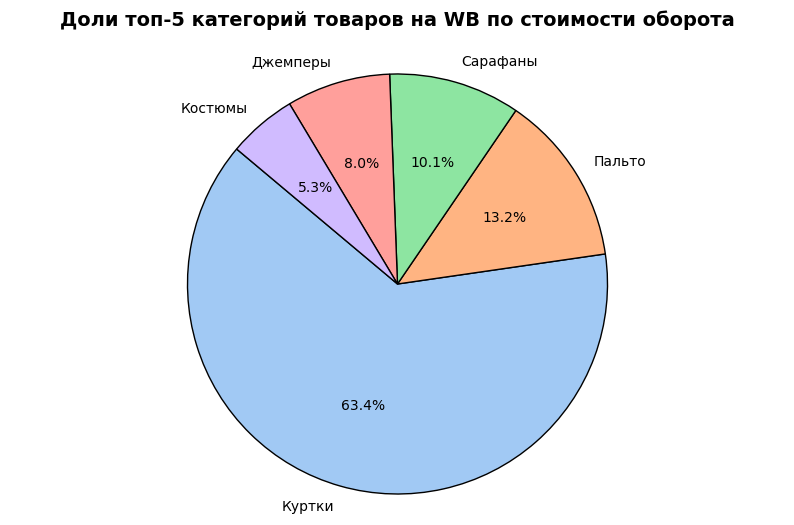

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Вбиваем чистые цифры из твоего успешного расчёта категорий
categories = ['Куртки', 'Пальто', 'Сарафаны', 'Джемперы', 'Костюмы']
values = [15257685.40, 3173114.00, 2436231.00, 1924759.80, 1274068.00]

# Настраиваем размер и сочные цвета
plt.figure(figsize=(10, 6))
colors = sns.color_palette('pastel')[0:5]

# Строим круговую диаграмму
plt.pie(values, 
        labels=categories, 
        colors=colors, 
        autopct='%1.1f%%', 
        startangle=140, 
        wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True})

plt.title('Доли топ-5 категорий товаров на WB по стоимости оборота', fontsize=14, fontweight='bold', pad=20)
plt.axis('equal') 

# Выводим на экран
plt.show()

In [7]:
# 1. Считаем общую выручку всего нашего очищенного датасета
total_revenue_all = top_revenue_brands['total_sales_rub'].sum()

# 2. Считаем процентную долю каждого бренда в общей выручке
top_revenue_brands['revenue_share_%'] = (top_revenue_brands['total_sales_rub'] / total_revenue_all) * 100

# 3. Пишем функцию для присвоения категории ABC
def abc_classification(share):
    if share >= 40: # Если один бренд держит огромную долю
        return 'A (Локомотив)'
    elif share >= 20:
        return 'B (Середняк)'
    else:
        return 'C (Аутсайдер)'

top_revenue_brands['ABC_category'] = top_revenue_brands['revenue_share_%'].apply(abc_classification)

print("--- 📊 ИТОГОВЫЙ ABC-АНАЛИЗ НАШЕЙ ТОРГОВОЙ МАТРИЦЫ ---")
display(top_revenue_brands[['brand_name', 'total_sales_rub', 'revenue_share_%', 'ABC_category']])

--- 📊 ИТОГОВЫЙ ABC-АНАЛИЗ НАШЕЙ ТОРГОВОЙ МАТРИЦЫ ---


,brand_name,total_sales_rub,revenue_share_%,ABC_category
2,ozy,8402047,44.612194,A (Локомотив)
0,are,6790815,36.057065,B (Середняк)
1,ika,3640659,19.330740,C (Аутсайдер)
3,вар,0,0.000000,C (Аутсайдер)
